# Cardiac Fibrosis Dataset
## Microscopy Image Cleaning and EDA

**Goal:** Check that the original microscopy images can be read, understand what each file contains, create previews, and summarize differences across images.

**Dataset:** 22 Leica `.lif` files in the `IMAGES` folder. 

**What this notebook produces:** File and channel inventories, image-quality tables, microscopy previews, EDA figures, and a handoff table for reproducibility.

> **Important:** We do not delete, resize, or modify the raw microscopy files. Here, "cleaning" means checking the data, recording inconsistencies, and preparing reliable metadata. The PNG previews are for visualization only.

---

## 0. Set up the project

This section loads the libraries and tells Python where to find the images. Keep the notebook inside the same folder as the `.lif` files, or update `IMAGE_DIR`.

We use `readlif` to read Leica images, `pandas` for tables, and `matplotlib` and `Pillow` for figures and previews.

In [1]:
# Run this cell once in your own Jupyter/VS Code environment.
%pip install readlif pandas numpy matplotlib pillow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from datetime import datetime
import re
import gc
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from readlif.reader import LifFile
from IPython.display import display

# Edit only this path if your folder is somewhere else.
IMAGE_DIR = Path.cwd()
OUTPUT_DIR = Path("outputs")
TABLE_DIR = OUTPUT_DIR / "tables"
PREVIEW_DIR = OUTPUT_DIR / "previews"
FIGURE_DIR = OUTPUT_DIR / "figures"

for folder in (TABLE_DIR, PREVIEW_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Read one z-slice and one timepoint as a consistent preliminary screen.
# Do not interpret these as full z-stack/time-series analysis.
Z_INDEX = 0
T_INDEX = 0
PREVIEW_MAX_SIDE = 1000

plt.rcParams.update({
    "figure.dpi": 115, "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 10,
    "font.size": 10,
})

assert IMAGE_DIR.exists(), f"Folder not found: {IMAGE_DIR.resolve()}"
files = sorted(IMAGE_DIR.glob("*.lif"))
print(f"Found {len(files)} .lif files in {IMAGE_DIR.resolve()}")
if len(files) != 22:
    print("NOTE: Your screenshot showed 22 files. Check the folder contents.")
if not files:
    raise FileNotFoundError("No .lif files found. Check IMAGE_DIR and extraction.")

Found 22 .lif files in /Users/deepaldeleena/Documents/D37-Semantic-Data-Lake/Images


**What we did:** We located the folder and created places to save tables, previews, and figures. 

**Result:** Python found all **22 `.lif` files**, so the notebook is reading from the correct folder.

## 1. Check filenames and identify images

A filename such as `191007_2_overview.lif` contains a six-digit date-like code, a sequence number, and the word `overview`. We use the **whole filename without `.lif`** as the unique image ID because multiple files can share a date code.

In [3]:
pattern = re.compile(r"^(\d{6})_(\d+)_overview$", re.IGNORECASE)

def parse_file_name(path):
    sample_id = path.stem
    match = pattern.match(sample_id)
    if match is None:
        return sample_id, None, None, False
    code, sequence = match.groups()
    try:
        date = datetime.strptime("20" + code, "%Y%m%d").date().isoformat()
    except ValueError:
        date = None
    return sample_id, date, int(sequence), True

name_rows = []
for file in files:
    sample_id, acq_date, seq, valid = parse_file_name(file)
    name_rows.append({
        "sample_id": sample_id,
        "filename": file.name,
        "date_code": file.stem[:6],
        "acquisition_date_inferred": acq_date,
        "sequence": seq,
        "filename_format_valid": valid,
        "file_size_mb": round(file.stat().st_size / (1024 ** 2), 2),
    })

names_df = pd.DataFrame(name_rows)
display(names_df)
print("Total files:", len(names_df))
print("Unique image IDs:", names_df["sample_id"].nunique())
print("Unique date codes:", names_df["date_code"].nunique())
print("Duplicate image IDs:", names_df["sample_id"].duplicated().sum())
print("Unexpected filename formats:", (~names_df["filename_format_valid"]).sum())

,sample_id,filename,date_code,acquisition_date_inferred,sequence,filename_format_valid,file_size_mb
0,190913_1_overview,190913_1_overview.lif,190913,2019-09-13,1,True,51.55
1,190930_1_overview,190930_1_overview.lif,190930,2019-09-30,1,True,1624.15
2,191007_1_overview,191007_1_overview.lif,191007,2019-10-07,1,True,1079.47
3,191007_2_overview,191007_2_overview.lif,191007,2019-10-07,2,True,915.85
4,191017_1_overview,191017_1_overview.lif,191017,2019-10-17,1,True,1570.24
5,191017_5_overview,191017_5_overview.lif,191017,2019-10-17,5,True,467.89
6,191101_1_overview,191101_1_overview.lif,191101,2019-11-01,1,True,964.88
7,191107_2_overview,191107_2_overview.lif,191107,2019-11-07,2,True,913.51
8,191108_1_overview,191108_1_overview.lif,191108,2019-11-08,1,True,2429.71
9,191114_3_overview,191114_3_overview.lif,191114,2019-11-14,3,True,1684.37


Total files: 22
Unique image IDs: 22
Unique date codes: 19
Duplicate image IDs: 0
Unexpected filename formats: 0


**What we did:** We checked whether filenames are consistently named and whether any image IDs repeat. 

**Result:** All **22 names** follow the expected pattern, with **22 unique IDs**, **19 date codes**, and **no duplicate image IDs**. This helps us match images to the ROI and mask files later.

## 2. Inspect image files and metadata

A `.lif` file can hold one or more image series. Here we look at the series, size, number of channels, and pixel spacing without changing the images. These details help the other team members locate and align the right tissue image.

In [4]:
def get_size_xy(image):
    """readlif image.dims is usually a named tuple with x and y."""
    return int(image.dims.x), int(image.dims.y)

def get_dim(image, name, default=1):
    value = getattr(image.dims, name, default)
    return int(value) if value is not None else default

def microns_per_pixel(image, axis):
    # readlif's X/Y scale is pixels per micrometer.
    try:
        scale_px_per_um = float(image.scale[axis])
        return round(1 / scale_px_per_um, 9) if scale_px_per_um > 0 else np.nan
    except (TypeError, ValueError, IndexError, ZeroDivisionError):
        return np.nan

def get_channel_bits(image, index):
    try:
        return int(image.bit_depth[index])
    except (TypeError, ValueError, IndexError, AttributeError):
        return np.nan

series_rows = []
inventory_rows = []

for file in files:
    sample_id = file.stem
    record = names_df.loc[names_df.sample_id == sample_id].iloc[0].to_dict()
    record.update({"read_status": "failed", "read_error": "", "series_count": 0,
                   "selected_series_index": np.nan, "selection_status": "unselected",
                   "width_px": np.nan, "height_px": np.nan,
                   "z_slices": np.nan, "timepoints": np.nan,
                   "channel_count": np.nan, "pixel_size_x_um": np.nan,
                   "pixel_size_y_um": np.nan})
    try:
        lif = LifFile(str(file))
        candidates = []
        for series_index, im in enumerate(lif.get_iter_image()):
            width, height = get_size_xy(im)
            info = {
                "sample_id": sample_id, "filename": file.name,
                "series_index": series_index,
                "series_name": str(getattr(im, "name", "")),
                "width_px": width, "height_px": height,
                "pixel_count": width * height,
                "z_slices": get_dim(im, "z"),
                "timepoints": get_dim(im, "t"),
                "mosaic_positions": get_dim(im, "m"),
                "channel_count": int(im.channels),
                "pixel_size_x_um": microns_per_pixel(im, 0),
                "pixel_size_y_um": microns_per_pixel(im, 1),
                "channel_bits": ",".join(str(get_channel_bits(im, c)) for c in range(int(im.channels))),
            }
            series_rows.append(info)
            candidates.append(info)

        record["series_count"] = len(candidates)
        if candidates:
            selected = max(candidates, key=lambda d: d["pixel_count"])
            record.update({key: selected[key] for key in [
                "width_px", "height_px", "z_slices", "timepoints",
                "channel_count", "pixel_size_x_um", "pixel_size_y_um"]})
            record["selected_series_index"] = selected["series_index"]
            record["selection_status"] = ("single_series" if len(candidates) == 1
                                          else "largest_XY_REVIEW")
            record["read_status"] = "metadata_loaded"
        else:
            record["read_error"] = "No readable image series found"
    except Exception as exc:
        record["read_error"] = f"{type(exc).__name__}: {str(exc)[:220]}"
        print(f"Could not read metadata for {file.name}: {record['read_error']}")
    finally:
        if "lif" in locals():
            del lif
    inventory_rows.append(record)

inventory_df = pd.DataFrame(inventory_rows)
series_df = pd.DataFrame(series_rows)
inventory_df.to_csv(TABLE_DIR / "image_inventory.csv", index=False)
series_df.to_csv(TABLE_DIR / "image_series.csv", index=False)

display(inventory_df[["sample_id", "read_status", "series_count", "selected_series_index",
                      "width_px", "height_px", "channel_count", "pixel_size_x_um",
                      "selection_status"]])
print("Readable image files:", (inventory_df.read_status == "metadata_loaded").sum(), "/", len(files))
print("Series requiring review:", (inventory_df.selection_status == "largest_XY_REVIEW").sum())

,sample_id,read_status,series_count,selected_series_index,width_px,height_px,channel_count,pixel_size_x_um,selection_status
0,190913_1_overview,metadata_loaded,1,0,5608,4807,1,1.513942,single_series
1,190930_1_overview,metadata_loaded,1,0,15525,10968,5,0.378442,single_series
2,191007_1_overview,metadata_loaded,1,0,9368,12080,5,0.378458,single_series
3,191007_2_overview,metadata_loaded,1,0,10308,9314,5,0.378455,single_series
4,191017_1_overview,metadata_loaded,1,0,17675,9314,5,0.378439,single_series
5,191017_5_overview,metadata_loaded,1,0,6562,7473,5,0.378476,single_series
6,191101_1_overview,metadata_loaded,1,0,11045,9158,5,0.378452,single_series
7,191107_2_overview,metadata_loaded,1,0,10285,9311,5,0.378455,single_series
8,191108_1_overview,metadata_loaded,1,0,13139,19387,5,0.378447,single_series
9,191114_3_overview,metadata_loaded,1,0,11213,15747,5,0.378452,single_series


Readable image files: 22 / 22
Series requiring review: 0


**What we did:** We checked each file's size, number of image series, dimensions, channels, and pixel spacing. 

**Result:** Metadata loaded for **all 22 files**, and each has **one image series**. Their dimensions differ, so downstream processing must use each image's own width and height. One file, `190913_1_overview`, has a noticeably larger pixel spacing (about **1.514 µm**) than most other files (about **0.378 µm**) and should be reviewed rather than automatically excluded.

## 3. Inspect microscopy channels

Each channel is a separate fluorescence image. We record channel number, display color, and acquisition bit depth.

**Note:** A display color (such as blue or gray) is not proof of the biological stain. The stain names still need confirmation from the original study or acquisition metadata.

In [5]:
def get_lut_names(lif, image):
    """Try to match Leica XML ImageDescription for the selected image."""
    width, height = get_size_xy(image)
    candidates = []
    root = getattr(lif, "xml_root", None)
    if root is None:
        return [None] * image.channels, "unavailable"

    for element in root.iter():
        if element.tag.split("}")[-1] != "Element":
            continue
        # Leica XML usually stores ImageDescription under Data/Image.
        desc = element.find("./Data/Image/ImageDescription")
        if desc is None:
            continue
        dimensions = {}
        for d in desc.findall("./Dimensions/DimensionDescription"):
            dimensions[d.get("DimID")] = d.get("NumberOfElements")
        channels = desc.findall("./Channels/ChannelDescription")
        if (dimensions.get("1") == str(width) and dimensions.get("2") == str(height)
                and len(channels) == image.channels):
            names = [ch.get("LUTName", "") or None for ch in channels]
            candidates.append((element.get("Name", ""), names))

    exact = [names for name, names in candidates if name == image.name]
    if len(exact) == 1:
        return exact[0], "matched_name_and_dimensions"
    if len(candidates) == 1:
        return candidates[0][1], "matched_unique_dimensions"
    return [None] * image.channels, "ambiguous_or_missing"

channel_rows = []
for rec in inventory_rows:
    if rec["read_status"] != "metadata_loaded":
        continue
    file = IMAGE_DIR / rec["filename"]
    try:
        lif = LifFile(str(file))
        im = lif.get_image(int(rec["selected_series_index"]))
        lut_names, lut_status = get_lut_names(lif, im)
        for c in range(int(im.channels)):
            channel_rows.append({
                "sample_id": rec["sample_id"], "filename": rec["filename"],
                "series_index": int(rec["selected_series_index"]),
                "channel_index": c, "channel_label": f"C{c + 1}",
                "lut_display_color": lut_names[c], "lut_match_status": lut_status,
                "acquisition_bit_depth": get_channel_bits(im, c),
                "stain_identity": "unverified",
                "stain_verification_status": "pending",
            })
    except Exception as exc:
        print("Channel metadata error:", file.name, str(exc)[:120])

channels_df = pd.DataFrame(channel_rows)
channels_df.to_csv(TABLE_DIR / "image_channels.csv", index=False)
display(channels_df.head(12))
print("Channel entries:", len(channels_df))

,sample_id,filename,series_index,channel_index,channel_label,lut_display_color,lut_match_status,acquisition_bit_depth,stain_identity,stain_verification_status
0,190913_1_overview,190913_1_overview.lif,0,0,C1,Gray,matched_unique_dimensions,12,unverified,pending
1,190930_1_overview,190930_1_overview.lif,0,0,C1,Blue,matched_unique_dimensions,12,unverified,pending
2,190930_1_overview,190930_1_overview.lif,0,1,C2,Green,matched_unique_dimensions,12,unverified,pending
3,190930_1_overview,190930_1_overview.lif,0,2,C3,Gray,matched_unique_dimensions,12,unverified,pending
4,190930_1_overview,190930_1_overview.lif,0,3,C4,Magenta,matched_unique_dimensions,12,unverified,pending
5,190930_1_overview,190930_1_overview.lif,0,4,C5,Red,matched_unique_dimensions,12,unverified,pending
6,191007_1_overview,191007_1_overview.lif,0,0,C1,Blue,matched_unique_dimensions,12,unverified,pending
7,191007_1_overview,191007_1_overview.lif,0,1,C2,Green,matched_unique_dimensions,12,unverified,pending
8,191007_1_overview,191007_1_overview.lif,0,2,C3,Gray,matched_unique_dimensions,12,unverified,pending
9,191007_1_overview,191007_1_overview.lif,0,3,C4,Magenta,matched_unique_dimensions,12,unverified,pending


Channel entries: 92


**What we did:** We listed the available channels so we know what image information is stored in each file. 

**Result:** There are **92 channel entries** across the 22 images. Some files have 1 or 2 channels, while others have 4 or 5. The channel display colors were extracted, but the **actual stains are still unverified**. This matters before anyone interprets a channel as DAPI, WGA, or another marker.

## 4. Check pixel quality and save image previews

We read the channels one at a time and check sampled raw pixel values (brightness, zero pixels, and possible saturation). We also create smaller PNGs to make visual review easier.

To keep the process manageable, the measurements use a **spatial sample from the first z-slice and timepoint**, not every pixel of every image. Display scaling is applied only to the saved previews; raw image values remain unchanged.

In [6]:
# These colors visualize channel indices, not particular stains.
OVERLAY_COLORS = [(0.25, 0.50, 1.0), (1.0, 0.48, 0.20),
                  (0.20, 0.85, 0.56), (0.78, 0.45, 0.95)]

def normalize_preview(sampled):
    """Create 8-bit image for viewing only; retain native pixels for statistics."""
    values = np.asarray(sampled, dtype=np.float32)
    low, high = np.percentile(values, [1, 99.5])
    if high <= low:
        low, high = float(values.min()), float(values.max())
    if high <= low:
        return np.zeros(values.shape, dtype=np.uint8), low, high
    result = np.clip((values - low) * (255.0 / (high - low)), 0, 255)
    return result.astype(np.uint8), round(float(low), 3), round(float(high), 3)

quality_rows = []
hist_rows = []
read_errors = []

for n, rec in enumerate(inventory_rows, start=1):
    if rec["read_status"] != "metadata_loaded":
        continue
    sid = rec["sample_id"]
    print(f"[{n}/{len(inventory_rows)}] {sid}")
    prepared = []
    try:
        lif = LifFile(str(IMAGE_DIR / rec["filename"]))
        im = lif.get_image(int(rec["selected_series_index"]))
        for c in range(int(im.channels)):
            try:
                frame = im.get_frame(z=Z_INDEX, t=T_INDEX, c=c)
                native = np.asarray(frame)
                if native.ndim != 2 or not np.issubdtype(native.dtype, np.number):
                    raise ValueError(f"Expected 2D numeric frame, got {native.shape} {native.dtype}")
                height, width = native.shape
                stride = max(1, math.ceil(max(height, width) / PREVIEW_MAX_SIDE))
                sampled = native[::stride, ::stride]
                values = sampled.astype(np.float64, copy=False)
                if values.size == 0:
                    raise ValueError("Empty sampled pixel array")

                bit_depth = get_channel_bits(im, c)
                detector_max = (2 ** int(bit_depth) - 1) if pd.notna(bit_depth) else np.nan
                n_pixels = values.size
                zero_pct = float(np.count_nonzero(values == 0) / n_pixels * 100)
                sat_pct = (float(np.count_nonzero(values >= detector_max) / n_pixels * 100)
                           if pd.notna(detector_max) else np.nan)
                p99 = float(np.percentile(values, 99))
                flags = []
                if zero_pct > 99.5:
                    flags.append("nearly_all_zero_REVIEW")
                if pd.notna(sat_pct) and sat_pct > 1:
                    flags.append("high_detector_saturation_REVIEW")
                if rec["selection_status"] == "largest_XY_REVIEW":
                    flags.append("series_selection_REVIEW")
                if get_dim(im, "z") > 1 or get_dim(im, "t") > 1:
                    flags.append("first_plane_only")

                quality_rows.append({
                    "sample_id": sid, "channel_index": c, "channel_label": f"C{c+1}",
                    "series_index": int(rec["selected_series_index"]),
                    "z_index": Z_INDEX, "t_index": T_INDEX,
                    "source_height_px": height, "source_width_px": width,
                    "native_dtype": str(native.dtype), "sample_stride": stride,
                    "sampled_pixel_count": n_pixels,
                    "min_intensity_sample": float(values.min()),
                    "max_intensity_sample": float(values.max()),
                    "mean_intensity_sample": float(values.mean()),
                    "median_intensity_sample": float(np.median(values)),
                    "std_intensity_sample": float(values.std()),
                    "p99_intensity_sample": p99,
                    "zero_pct_sample": zero_pct,
                    "detector_max": detector_max,
                    "detector_saturated_pct_sample": sat_pct,
                    "review_flags": ";".join(flags) if flags else "none_auto_detected",
                    "visual_review_status": "pending",
                })

                # Histogram is based on sampled RAW values, not preview-normalized pixels.
                h_min, h_max = float(values.min()), float(values.max())
                if h_max == h_min:
                    h_max += 1
                counts, edges = np.histogram(values, bins=64, range=(h_min, h_max))
                for i, count in enumerate(counts):
                    hist_rows.append({"sample_id": sid, "channel_index": c,
                                      "bin_start": float(edges[i]),
                                      "bin_end": float(edges[i+1]),
                                      "count": int(count)})

                preview, lo, hi = normalize_preview(sampled)
                out = PREVIEW_DIR / f"{sid}_C{c+1}.png"
                Image.fromarray(preview).save(out)
                prepared.append(preview)
                print(f"    C{c+1}: {native.shape}, {native.dtype}, "
                      f"mean≈{values.mean():.2f}, zeros≈{zero_pct:.1f}%")
                del native, frame, sampled, values
                gc.collect()
            except Exception as exc:
                message = f"{type(exc).__name__}: {str(exc)[:160]}"
                read_errors.append({"sample_id": sid, "channel_index": c, "error": message})
                print(f"    C{c+1} FAILED: {message}")

        # Only overlay channels with the same sampled shape.
        if len(prepared) >= 2 and len({a.shape for a in prepared}) == 1:
            overlay = np.zeros((*prepared[0].shape, 3), dtype=np.float32)
            for c, preview in enumerate(prepared):
                color = np.array(OVERLAY_COLORS[c % len(OVERLAY_COLORS)], dtype=np.float32)
                overlay += (preview.astype(np.float32) / 255.0)[..., None] * color
            overlay = (np.clip(overlay, 0, 1) * 255).astype(np.uint8)
            Image.fromarray(overlay).save(PREVIEW_DIR / f"{sid}_overlay.png")
    except Exception as exc:
        read_errors.append({"sample_id": sid, "channel_index": np.nan,
                            "error": f"{type(exc).__name__}: {str(exc)[:160]}"})
        print("  FILE FAILED:", exc)
    finally:
        if "im" in locals():
            del im
        if "lif" in locals():
            del lif
        gc.collect()

quality_df = pd.DataFrame(quality_rows)
hist_df = pd.DataFrame(hist_rows)
quality_df.to_csv(TABLE_DIR / "image_quality.csv", index=False)
hist_df.to_csv(TABLE_DIR / "intensity_histograms.csv", index=False)
pd.DataFrame(read_errors, columns=["sample_id", "channel_index", "error"]).to_csv(
    TABLE_DIR / "image_read_errors.csv", index=False)
print("Quality rows:", len(quality_df), "| Channel read errors:", len(read_errors))
display(quality_df.head())

[1/22] 190913_1_overview
    C1: (4807, 5608), uint16, mean≈18.11, zeros≈69.5%
[2/22] 190930_1_overview
    C1: (10968, 15525), uint16, mean≈5.60, zeros≈37.0%
    C2: (10968, 15525), uint16, mean≈1.28, zeros≈61.7%
    C3: (10968, 15525), uint16, mean≈9.91, zeros≈32.0%
    C4: (10968, 15525), uint16, mean≈2.09, zeros≈40.0%
    C5: (10968, 15525), uint16, mean≈7.70, zeros≈49.8%
[3/22] 191007_1_overview
    C1: (12080, 9368), uint16, mean≈6.55, zeros≈20.9%
    C2: (12080, 9368), uint16, mean≈1.93, zeros≈47.4%
    C3: (12080, 9368), uint16, mean≈16.66, zeros≈10.1%
    C4: (12080, 9368), uint16, mean≈4.20, zeros≈21.2%
    C5: (12080, 9368), uint16, mean≈8.72, zeros≈32.7%
[4/22] 191007_2_overview
    C1: (9314, 10308), uint16, mean≈10.01, zeros≈17.2%
    C2: (9314, 10308), uint16, mean≈3.07, zeros≈42.6%
    C3: (9314, 10308), uint16, mean≈15.16, zeros≈4.8%
    C4: (9314, 10308), uint16, mean≈3.57, zeros≈22.8%
    C5: (9314, 10308), uint16, mean≈6.53, zeros≈28.1%
[5/22] 191017_1_overview
    

,sample_id,channel_index,channel_label,series_index,z_index,t_index,source_height_px,source_width_px,native_dtype,sample_stride,...,max_intensity_sample,mean_intensity_sample,median_intensity_sample,std_intensity_sample,p99_intensity_sample,zero_pct_sample,detector_max,detector_saturated_pct_sample,review_flags,visual_review_status
0,190913_1_overview,0,C1,0,0,0,4807,5608,uint16,6,...,570.0,18.110641,0.0,54.180085,280.0,69.459106,4095,0.0,none_auto_detected,pending
1,190930_1_overview,0,C1,0,0,0,10968,15525,uint16,16,...,115.0,5.597364,1.0,8.296340,33.0,37.046356,4095,0.0,none_auto_detected,pending
2,190930_1_overview,1,C2,0,0,0,10968,15525,uint16,16,...,139.0,1.281939,0.0,2.970071,11.0,61.689731,4095,0.0,none_auto_detected,pending
3,190930_1_overview,2,C3,0,0,0,10968,15525,uint16,16,...,138.0,9.906203,3.0,13.713408,55.0,32.031238,4095,0.0,none_auto_detected,pending
4,190930_1_overview,3,C4,0,0,0,10968,15525,uint16,16,...,152.0,2.094734,1.0,4.599362,17.0,39.991533,4095,0.0,none_auto_detected,pending


**What we did:** We sampled the raw brightness values in each channel to screen for unusual images, then saved smaller PNG previews. 

**Result:** All **92 channels were read successfully**, with **zero reported read errors**. Differences in brightness and zero-valued pixels are worth inspecting, but they do not by themselves mean an image is poor quality. The original `.lif` images were not changed.

## 5. Explore the images with visualizations

The figures below help us spot differences across the files. They describe image properties, **not** fibrosis severity or disease status.

### 5A. File size and image dimensions

These two plots compare how much storage each file uses and how large its image is in pixels.

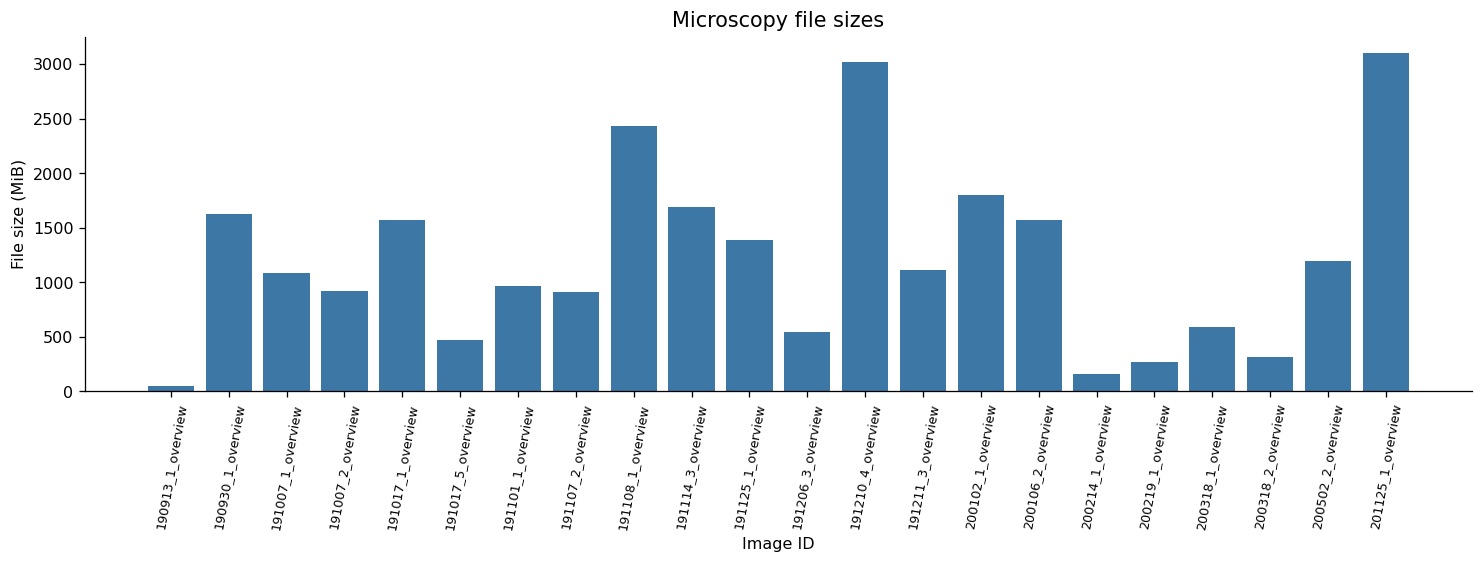

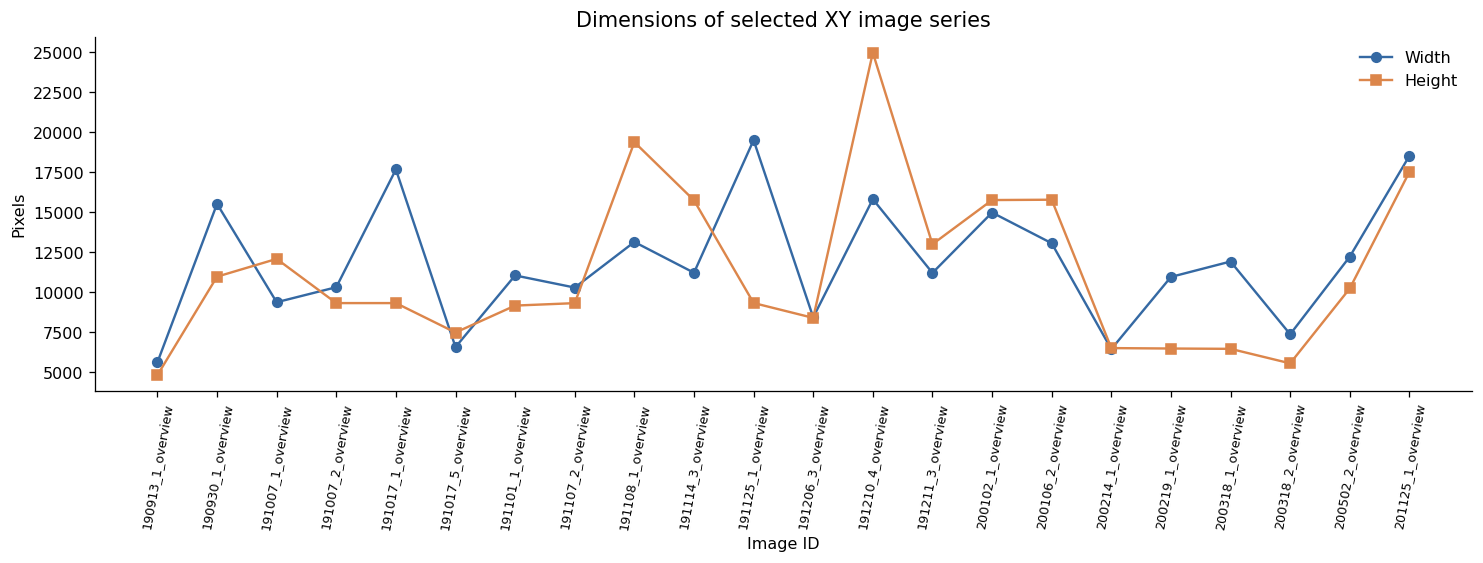

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_df = inventory_df.sort_values("sample_id")
colors = ["#E08B54" if s != "metadata_loaded" else "#3D77A6"
          for s in plot_df["read_status"]]
ax.bar(plot_df["sample_id"], plot_df["file_size_mb"], color=colors)
ax.set_title("Microscopy file sizes")
ax.set_ylabel("File size (MiB)")
ax.set_xlabel("Image ID")
ax.tick_params(axis="x", rotation=80, labelsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "file_sizes.png", bbox_inches="tight")
plt.show()

valid = inventory_df.dropna(subset=["width_px", "height_px"]).sort_values("sample_id")
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(valid.sample_id, valid.width_px, "o-", label="Width", color="#3569A3")
ax.plot(valid.sample_id, valid.height_px, "s-", label="Height", color="#DC864B")
ax.set_title("Dimensions of selected XY image series")
ax.set_ylabel("Pixels")
ax.set_xlabel("Image ID")
ax.tick_params(axis="x", rotation=80, labelsize=8)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "image_dimensions.png", bbox_inches="tight")
plt.show()

**What we did:** We compared image sizes and pixel dimensions to see how consistent the dataset is. 

**What we found:** The files vary substantially in size and resolution. This is important because large images take more memory and ROIs must be mapped using the **correct dimensions for each image**, not one shared size.

### 5B. Channel availability

This heatmap shows whether each numbered channel is present in each image. It does not identify the biological stain.

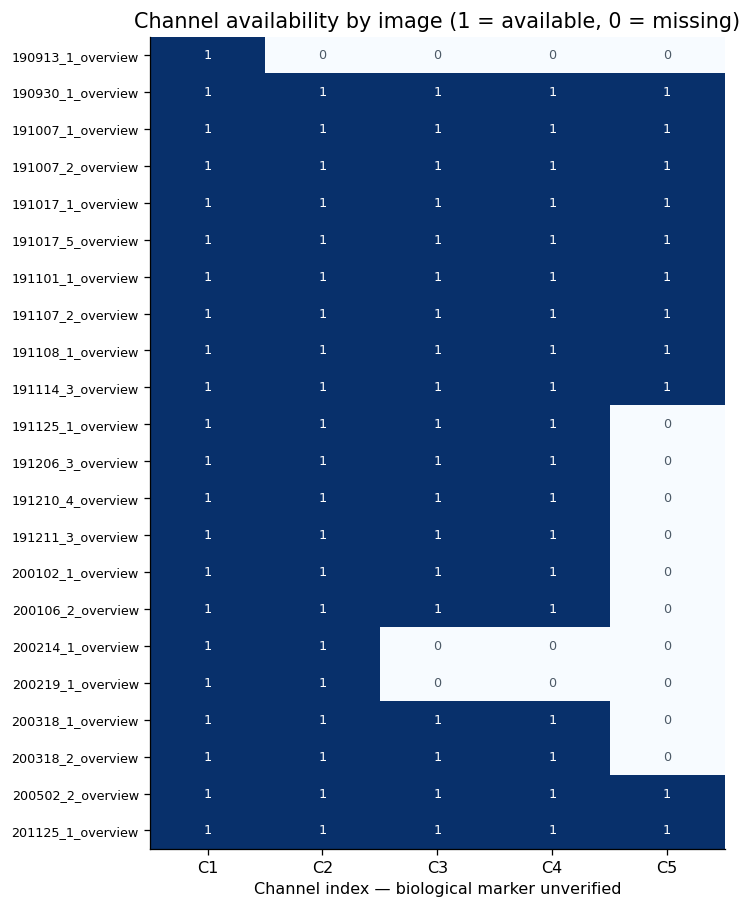

In [8]:
if not channels_df.empty:
    availability = (channels_df.assign(present=1)
                    .pivot_table(index="sample_id", columns="channel_label",
                                 values="present", aggfunc="max", fill_value=0))
    order = sorted(availability.columns, key=lambda c: int(c[1:]))
    availability = availability.reindex(index=sorted(inventory_df.sample_id),
                                        columns=order, fill_value=0)
    fig, ax = plt.subplots(figsize=(max(5, len(order) * 1.3), 8))
    ax.imshow(availability.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(len(order)), labels=order)
    ax.set_yticks(range(len(availability.index)), labels=availability.index, fontsize=8)
    ax.set_title("Channel availability by image (1 = available, 0 = missing)")
    ax.set_xlabel("Channel index — biological marker unverified")
    for y in range(len(availability.index)):
        for x in range(len(order)):
            ax.text(x, y, str(int(availability.iloc[y, x])), ha="center", va="center",
                    fontsize=8, color="white" if availability.iloc[y, x] else "#4C5966")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "channel_availability.png", bbox_inches="tight")
    plt.show()

**What we did:** We visualized which channel numbers are present for each image. 

**What we found:** Channel availability is not identical across the dataset—there are **1-, 2-, 4-, and 5-channel** images. We should not assume every image contains the same stains or interpret C1/C2 as the same biological markers until they are verified.

### 5C. Pixel-intensity and background comparisons

These plots compare the sampled mean brightness and the percentage of zero-valued pixels by image and channel.

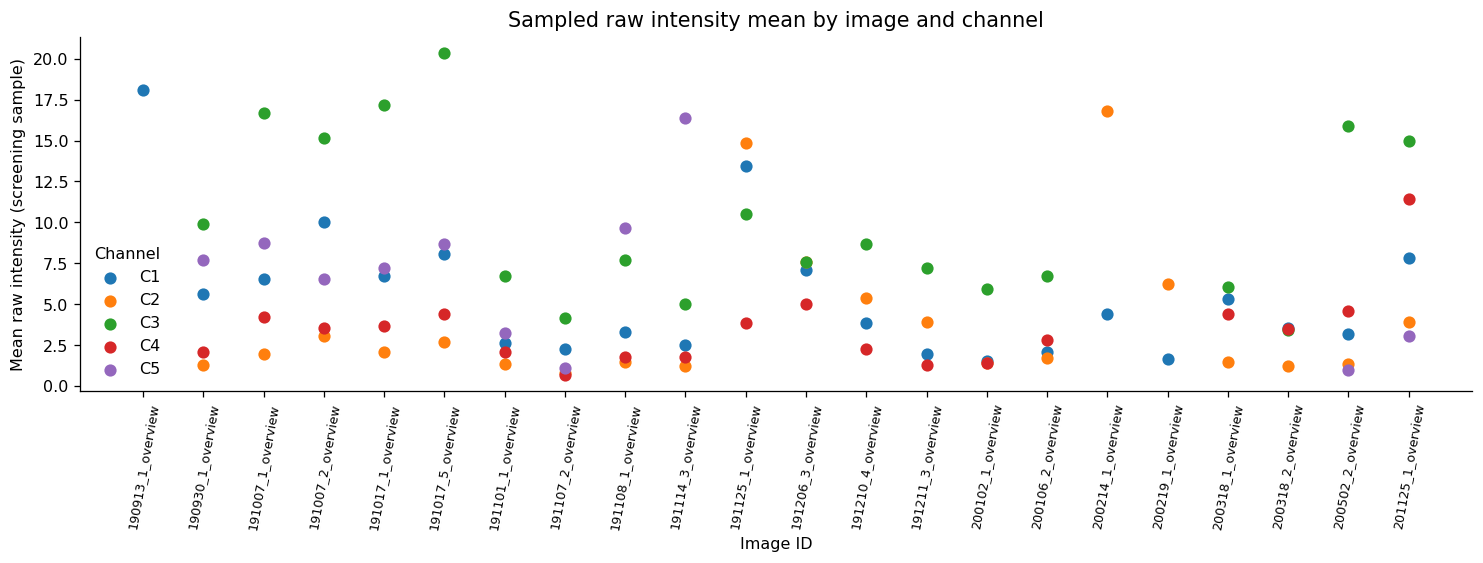

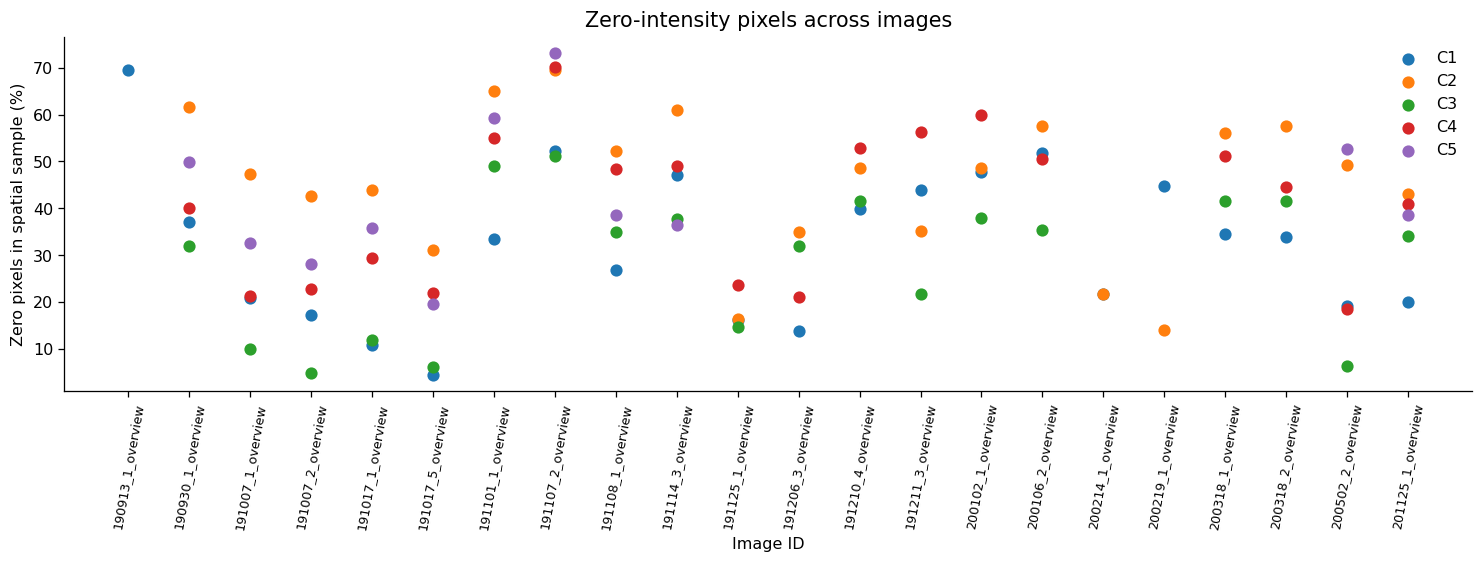

In [9]:
if not quality_df.empty:
    fig, ax = plt.subplots(figsize=(13, 5))
    for c, group in quality_df.groupby("channel_index"):
        ax.scatter(group.sample_id, group.mean_intensity_sample,
                   label=f"C{c+1}", s=44)
    ax.set_title("Sampled raw intensity mean by image and channel")
    ax.set_ylabel("Mean raw intensity (screening sample)")
    ax.set_xlabel("Image ID")
    ax.tick_params(axis="x", rotation=80, labelsize=8)
    ax.legend(title="Channel", frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "mean_intensity_by_channel.png", bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(13, 5))
    for c, group in quality_df.groupby("channel_index"):
        ax.scatter(group.sample_id, group.zero_pct_sample,
                   label=f"C{c+1}", s=44)
    ax.set_title("Zero-intensity pixels across images")
    ax.set_ylabel("Zero pixels in spatial sample (%)")
    ax.set_xlabel("Image ID")
    ax.tick_params(axis="x", rotation=80, labelsize=8)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "zero_pixel_percentage.png", bbox_inches="tight")
    plt.show()

**What we did:** We compared sampled brightness and black (zero-valued) pixels to identify images that might need closer inspection. 

**What we found:** Both measurements vary by channel and image. This is useful for **quality screening**, but low intensity or many dark pixels can be normal in microscopy and are **not evidence of fibrosis or disease**.

### 5D. Pixel-intensity histogram for one image

This figure shows the distribution of **sampled raw pixel intensities** for `200214_1_overview` (or the first available sample if that file is missing).

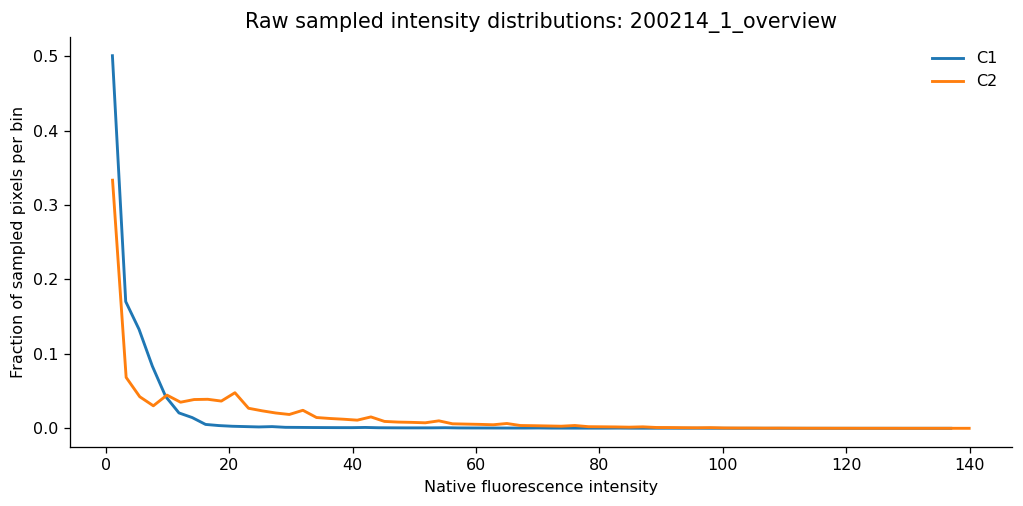

In [10]:
if not hist_df.empty:
    EXAMPLE_ID = "200214_1_overview"   # Change if this sample is missing
    if EXAMPLE_ID not in set(hist_df.sample_id):
        EXAMPLE_ID = sorted(hist_df.sample_id.unique())[0]
    example = hist_df[hist_df.sample_id == EXAMPLE_ID]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for c, group in example.groupby("channel_index"):
        centers = (group.bin_start + group.bin_end) / 2
        fraction = group["count"] / group["count"].sum()
        ax.plot(centers, fraction, label=f"C{c+1}", linewidth=1.8)
    ax.set_title(f"Raw sampled intensity distributions: {EXAMPLE_ID}")
    ax.set_xlabel("Native fluorescence intensity")
    ax.set_ylabel("Fraction of sampled pixels per bin")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "intensity_histograms.png", bbox_inches="tight")
    plt.show()

**What we did:** We plotted the raw brightness distribution for one sample to see how pixel values are spread. 

**What we found:** The channels have different intensity patterns. This helps us understand the images before analysis, but the plot alone cannot identify the stain or compare disease severity.

### 5E. Microscopy preview gallery

This gallery shows a few saved C1 previews from different files. The displayed brightness was adjusted to make tissue structures visible, but that adjustment is not used for numerical measurements.

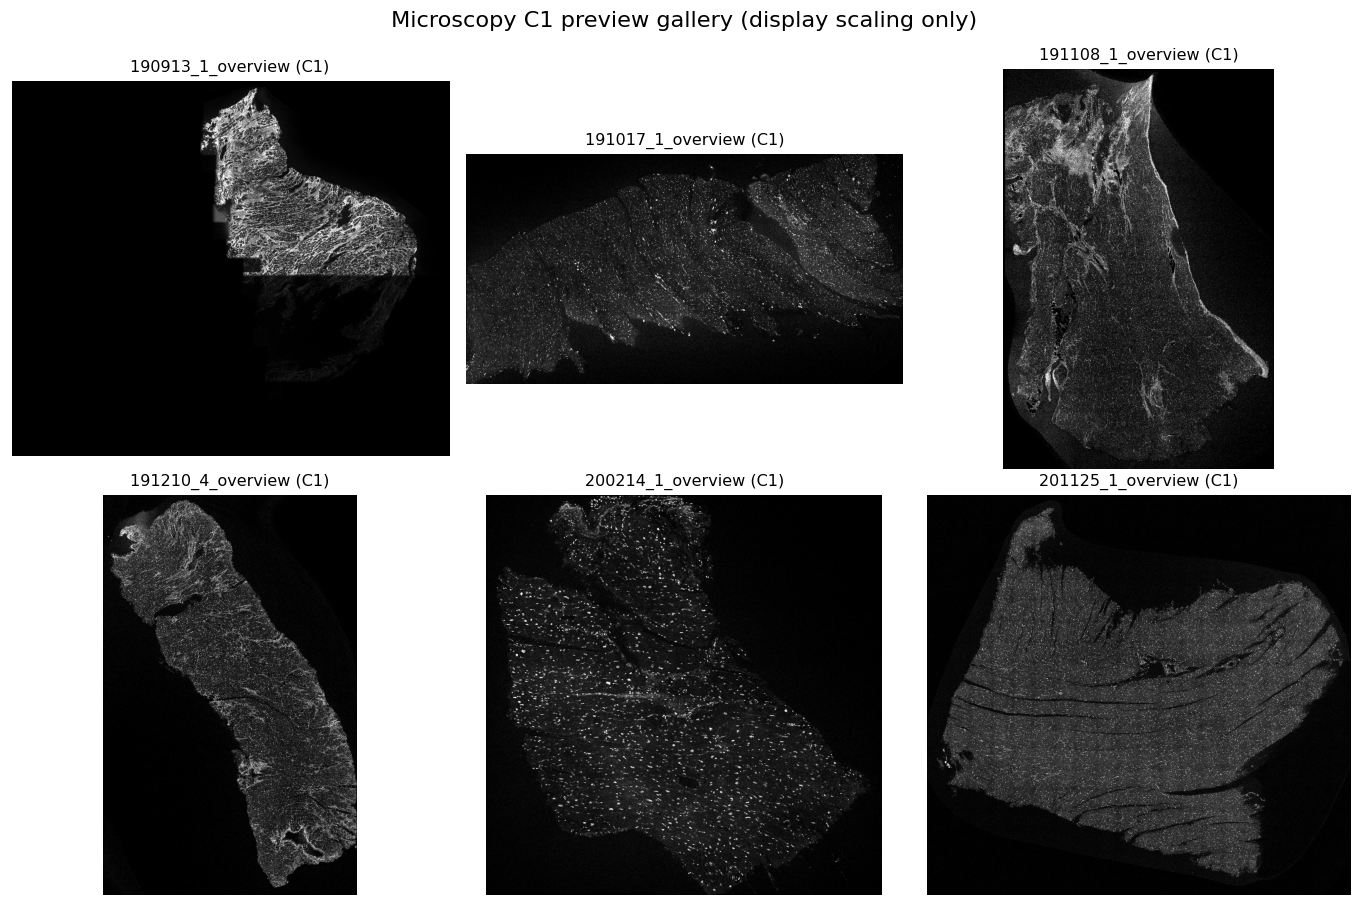

In [11]:
previews = sorted(PREVIEW_DIR.glob("*_C1.png"))
if previews:
    positions = np.unique(np.linspace(0, len(previews)-1, min(6, len(previews)), dtype=int))
    chosen = [previews[i] for i in positions]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, path in zip(axes.flat, chosen):
        ax.imshow(Image.open(path), cmap="gray")
        ax.set_title(path.stem.replace("_C1", "") + " (C1)", fontsize=10)
        ax.axis("off")
    fig.suptitle("Microscopy C1 preview gallery (display scaling only)", fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "representative_tissue_images.png", bbox_inches="tight")
    plt.show()
else:
    print("No previews exist yet; review image_read_errors.csv")

**What we did:** We placed multiple image previews side by side to make tissue appearance easier to compare. 

**What we found:** The gallery is useful for checking visible structures and possible artifacts. These six images were chosen by filename order, **not** because they are confirmed healthy or heart-failure examples. Review the individual channel PNGs and overlays as well.

## 6. Prepare the manual quality-review checklist

Numbers alone cannot tell us whether an image is blurry, has stitching artifacts, shows the correct tissue region, or uses the expected stain. We make review tables so these checks can be filled in after looking at the previews and original methodology.

In [12]:
# One review row per original LIF file. Do not drop rows when pixels fail to load.
flags = (quality_df.groupby("sample_id")["review_flags"]
         .apply(lambda s: ";".join(sorted(set(s)))).rename("auto_review_flags")
         if not quality_df.empty else pd.Series(dtype=str, name="auto_review_flags"))
review_df = inventory_df[["sample_id", "filename", "read_status", "selection_status"]].copy()
review_df = review_df.merge(flags, left_on="sample_id", right_index=True, how="left")
review_df["visual_review_status"] = "pending"
review_df["tissue_visible"] = ""
review_df["blur_or_stitch_artifacts"] = ""
review_df["series_and_plane_confirmed"] = ""
review_df["channel_identity_verified"] = ""
review_df["review_notes"] = ""
review_df.to_csv(TABLE_DIR / "manual_review_template.csv", index=False)
display(review_df.head(10))

# Separate review sheet for confirming which biological stain each channel represents.
channel_review = channels_df[["sample_id", "channel_index", "channel_label",
                               "lut_display_color", "stain_identity",
                               "stain_verification_status"]].copy()
channel_review["evidence_or_source"] = ""
channel_review.to_csv(TABLE_DIR / "channel_labels_review_template.csv", index=False)

,sample_id,filename,read_status,selection_status,auto_review_flags,visual_review_status,tissue_visible,blur_or_stitch_artifacts,series_and_plane_confirmed,channel_identity_verified,review_notes
0,190913_1_overview,190913_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
1,190930_1_overview,190930_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
2,191007_1_overview,191007_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
3,191007_2_overview,191007_2_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
4,191017_1_overview,191017_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
5,191017_5_overview,191017_5_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
6,191101_1_overview,191101_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
7,191107_2_overview,191107_2_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
8,191108_1_overview,191108_1_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,
9,191114_3_overview,191114_3_overview.lif,metadata_loaded,single_series,none_auto_detected,pending,,,,,


**What we did:** We created two checklists for visual image quality and for confirming stain names. 


## 7. Create the file to share

Finally, we combine the image metadata and quality checks into one table with **one row per original `.lif` file**. 

In [13]:
handoff = inventory_df.copy()
if not quality_df.empty:
    counted = (quality_df.groupby("sample_id")
               .agg(channels_quality_checked=("channel_index", "nunique"),
                    mean_zero_pct=("zero_pct_sample", "mean"),
                    max_detector_saturation_pct=("detector_saturated_pct_sample", "max"))
               .reset_index())
    handoff = handoff.merge(counted, on="sample_id", how="left")
else:
    handoff["channels_quality_checked"] = np.nan
    handoff["mean_zero_pct"] = np.nan
    handoff["max_detector_saturation_pct"] = np.nan

handoff["disease_group"] = pd.NA  # Do NOT infer from file names
handoff["patient_id"] = pd.NA     # Do NOT infer from file dates
handoff.to_csv(TABLE_DIR / "image_handoff.csv", index=False)

print("Original file count:", len(inventory_df))
print("Metadata successfully loaded:", (inventory_df.read_status == "metadata_loaded").sum())
print("All channel quality checks completed:", len(quality_df))
print("Image series to review:", (inventory_df.selection_status == "largest_XY_REVIEW").sum())
print("Pixel reading errors:", len(read_errors))
print("Output tables:", TABLE_DIR.resolve())
print("Preview images:", PREVIEW_DIR.resolve())
print("EDA figures:", FIGURE_DIR.resolve())
display(handoff.head())

Original file count: 22
Metadata successfully loaded: 22
All channel quality checks completed: 92
Image series to review: 0
Pixel reading errors: 0
Output tables: /Users/deepaldeleena/Documents/D37-Semantic-Data-Lake/Images/outputs/tables
Preview images: /Users/deepaldeleena/Documents/D37-Semantic-Data-Lake/Images/outputs/previews
EDA figures: /Users/deepaldeleena/Documents/D37-Semantic-Data-Lake/Images/outputs/figures


,sample_id,filename,date_code,acquisition_date_inferred,sequence,filename_format_valid,file_size_mb,read_status,read_error,series_count,...,z_slices,timepoints,channel_count,pixel_size_x_um,pixel_size_y_um,channels_quality_checked,mean_zero_pct,max_detector_saturation_pct,disease_group,patient_id
0,190913_1_overview,190913_1_overview.lif,190913,2019-09-13,1,True,51.55,metadata_loaded,,1,...,1,1,1,1.513942,1.513987,1,69.459106,0.0,<NA>,<NA>
1,190930_1_overview,190930_1_overview.lif,190930,2019-09-30,1,True,1624.15,metadata_loaded,,1,...,1,1,5,0.378442,0.378452,5,44.109316,0.0,<NA>,<NA>
2,191007_1_overview,191007_1_overview.lif,191007,2019-10-07,1,True,1079.47,metadata_loaded,,1,...,1,1,5,0.378458,0.378449,5,26.432762,0.0,<NA>,<NA>
3,191007_2_overview,191007_2_overview.lif,191007,2019-10-07,2,True,915.85,metadata_loaded,,1,...,1,1,5,0.378455,0.378459,5,23.099765,0.0,<NA>,<NA>
4,191017_1_overview,191017_1_overview.lif,191017,2019-10-17,1,True,1570.24,metadata_loaded,,1,...,1,1,5,0.378439,0.378459,5,26.367196,0.0,<NA>,<NA>


We joined the main results into one file that other team members can use. 

**Result:** `image_handoff.csv` includes **22 image rows**, and the notebook reports **zero pixel-read failures**. The `disease_group` and `patient_id` fields are intentionally empty because they cannot be determined safely from filenames alone.